# Práctica: Pronóstico de demanda eléctrica (todos los modelos) — Red eléctrica de Bangladesh

#### Universidad Autónoma de Chihuahua | Facultad de Ingeniería | Maestría en Ciencias de la Computación
#### Materia: Machine Learning
#### Actividad: Práctica — Regresión de la demanda horaria (`demand_mw`)
#### Catedrático: Dra. Olanda Prieto Ordaz
#### Nombre Alumno: Andrea Georgina Rodríguez Pacheco
#### Matrícula: 395699
#### Fecha: 9 de noviembre de 2026

In [2]:
import os
import time
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, StackingRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=FutureWarning)

# III. Preparación de los datos

## Fase 1. Selección y preparación de los datos

### 1. Inspección inicial
Dimensiones, tipos, faltantes, duplicados y rango de la variable objetivo. En esta etapa no se realizan transformaciones dependientes de los datos.

In [7]:
zip_path = "../pgcb+hourly+generation+dataset+(bangladesh).zip"

with zipfile.ZipFile(zip_path) as z:
    X = pd.read_excel(z.open("PGCB_date_power_demand.xlsx"))

TARGET = "demand_mw"

X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92650 entries, 0 to 92649
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              92650 non-null  datetime64[ns]
 1   generation_mw         92650 non-null  float64       
 2   demand_mw             92650 non-null  int64         
 3   load_shedding         92650 non-null  int64         
 4   gas                   92650 non-null  int64         
 5   liquid_fuel           92650 non-null  int64         
 6   coal                  92650 non-null  int64         
 7   hydro                 92650 non-null  int64         
 8   solar                 70517 non-null  float64       
 9   wind                  18676 non-null  float64       
 10  india_bheramara_hvdc  92650 non-null  int64         
 11  india_tripura         92650 non-null  int64         
 12  india_adani           7338 non-null   float64       
 13  nepal           

In [8]:
border = "-" * 40
print("Dimensiones:", X.shape)
print(border)
print("Registros duplicados completos:", X.duplicated().sum())
print("Marcas de tiempo repetidas:", X["datetime"].duplicated().sum())
print(border)
print(f"Rango de {TARGET}: {X[TARGET].min():,} → {X[TARGET].max():,}")
print(f"Faltantes en {TARGET}: {X[TARGET].isna().sum()}")
print(border)
# Relación contable entre demanda, generación y load shedding
gap = X["demand_mw"] - X["generation_mw"] - X["load_shedding"]
print(f"Registros con demand_mw = generation_mw + load_shedding (±1 MW): {(gap.abs() <= 1).mean():.1%}")

Dimensiones: (92650, 15)
----------------------------------------
Registros duplicados completos: 160
Marcas de tiempo repetidas: 432
----------------------------------------
Rango de demand_mw: 6 → 156,050
Faltantes en demand_mw: 0
----------------------------------------
Registros con demand_mw = generation_mw + load_shedding (±1 MW): 84.8%


### Observaciones
| Aspecto | Resultado |
|---|---|
| Tamaño | 92,650 registros × 15 columnas |
| Duplicados | 160 registros completos y 432 marcas de tiempo repetidas |
| Rango de `demand_mw` | 6 → 156,050 MW (valores imposibles; la capacidad real es < 17,000 MW) |
| Faltantes en `demand_mw` | 0 |
| `demand_mw = generation_mw + load_shedding` | 84.8% de los registros (±1 MW) |

- La última fila confirma la **fuga de información**: si se usaran la generación y el load shedding de la misma hora, el modelo solo tendría que sumarlos.

## Fase 2. Partición y EDA

### 2. Definición de X e y y prevención de fuga de información

**Limpieza previa a la partición** (reglas fijas, iguales a las prácticas anteriores): eliminación de duplicados, orden cronológico, eliminación de valores físicamente imposibles y periodo de estudio de los últimos tres años.

**Predictores excluidos por fuga de información.** En PGCB la demanda se registra prácticamente como generación + load shedding. Si se usaran variables de la misma hora, el modelo aprendería una suma y no un pronóstico:

| Variable | Motivo de exclusión |
|---|---|
| `generation_mw`, `load_shedding` | Su suma reproduce `demand_mw` |
| `gas`, `liquid_fuel`, `coal`, `hydro`, `solar`, `wind` | Componentes de la generación de la misma hora |
| `india_*`, `nepal` | Importaciones de la misma hora (parte del suministro) |
| `remarks` | Etiqueta de periodo pico con 93% de faltantes |

**Predictores incluidos** (disponibles un día antes de la hora pronosticada):
- **Rezagos de la demanda:** `demand_lag_24h` (misma hora del día anterior) y `demand_lag_168h` (misma hora de la semana anterior). Se calculan sobre la serie horaria completa, solo con valores del pasado.
- **Calendario y clima** (Feature Engineering, sección 5.3). Para el clima se usaría el pronóstico meteorológico.

In [9]:
X = X.drop_duplicates().reset_index(drop=True)
X = X.sort_values("datetime").drop_duplicates(subset="datetime", keep="last").reset_index(drop=True)

max_mw = {
    "generation_mw": 20000, "demand_mw": 20000, "load_shedding": 5000,
    "gas": 15000, "liquid_fuel": 10000, "coal": 10000, "hydro": 1000,
    "india_bheramara_hvdc": 2000, "india_tripura": 500, "india_adani": 3000,
}
invalid = np.zeros(len(X), dtype=bool)
for col, limit in max_mw.items():
    invalid |= X[col] > limit
print("Registros con valores imposibles eliminados:", invalid.sum())
X = X[~invalid].reset_index(drop=True)

# Serie horaria de demanda (media por hora) sobre todo el histórico limpio, para calcular rezagos solo con el pasado
hourly_demand = X.groupby(X["datetime"].dt.floor("h"))[TARGET].mean()


def add_lag_features(df, series):
    df = df.copy()
    hour = df["datetime"].dt.floor("h")
    df["demand_lag_24h"] = series.reindex(hour - pd.Timedelta(hours=24)).to_numpy()
    df["demand_lag_168h"] = series.reindex(hour - pd.Timedelta(hours=168)).to_numpy()
    return df


study_years = 3
end_date = X["datetime"].max()
X = X[X["datetime"] > end_date - pd.DateOffset(years=study_years)].reset_index(drop=True)
print("Periodo de estudio:", X["datetime"].min(), "→", X["datetime"].max(), "| registros:", len(X))

leak_columns = ["generation_mw", "load_shedding", "gas", "liquid_fuel", "coal", "hydro", "solar", "wind",
                "india_bheramara_hvdc", "india_tripura", "india_adani", "nepal", "remarks"]
X_var = add_lag_features(X[["datetime"]], hourly_demand)
y_var = X[TARGET].copy()
print("X:", X_var.shape, "| y:", y_var.shape)
print("Rezagos faltantes:", X_var[["demand_lag_24h", "demand_lag_168h"]].isna().sum().to_dict())

Registros con valores imposibles eliminados: 168
Periodo de estudio: 2022-06-17 13:00:00 → 2025-06-17 12:00:00 | registros: 27285
X: (27285, 3) | y: (27285,)
Rezagos faltantes: {'demand_lag_24h': 107, 'demand_lag_168h': 107}


### 3. Partición Train/Test temporal
Partición **cronológica** 80/20 con `shuffle=False`, igual que en las prácticas anteriores. A partir de aquí Test queda aislado hasta la evaluación final.

Train: (21828, 3) | 2022-06-17 13:00:00 → 2024-11-10 18:00:00
Test:  (5457, 3) | 2024-11-10 18:30:00 → 2025-06-17 12:00:00


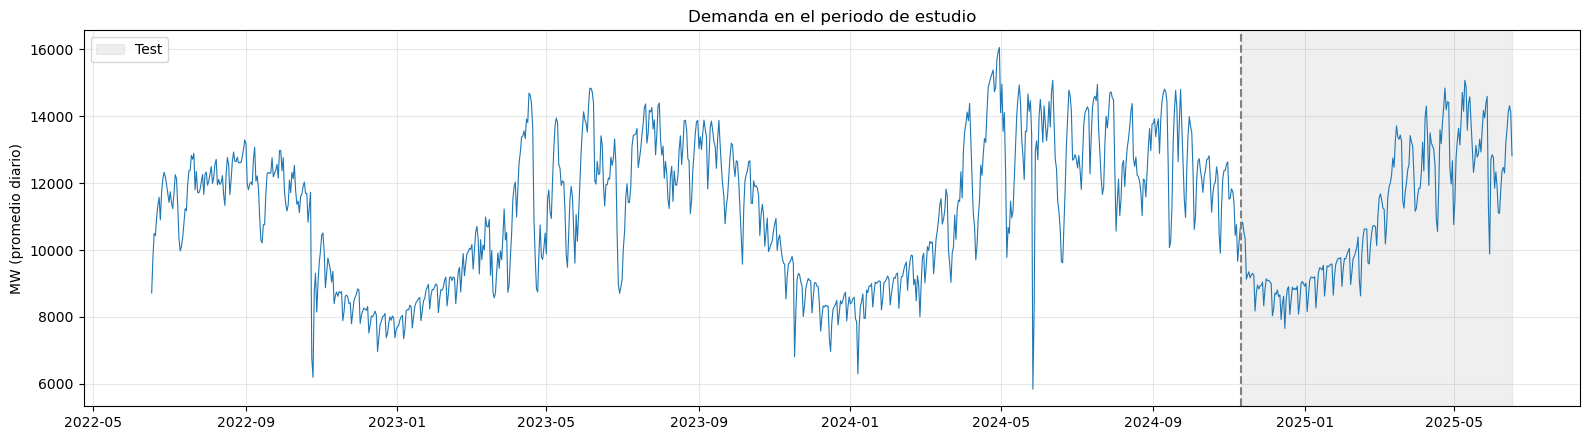

In [10]:
train_set_x, test_set_x, train_set_y, test_set_y = train_test_split(
    X_var, y_var, test_size=0.2, shuffle=False
)
print("Train:", train_set_x.shape, "|", train_set_x["datetime"].min(), "→", train_set_x["datetime"].max())
print("Test: ", test_set_x.shape, "|", test_set_x["datetime"].min(), "→", test_set_x["datetime"].max())
assert train_set_x["datetime"].max() < test_set_x["datetime"].min()

daily = y_var.groupby(X_var["datetime"].dt.date).mean()
daily.index = pd.to_datetime(daily.index)
split_date = test_set_x["datetime"].min()
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(daily.index, daily.values, linewidth=0.8)
ax.axvspan(split_date, daily.index.max(), color="gray", alpha=0.12, label="Test")
ax.axvline(split_date, color="gray", linestyle="--")
ax.set_ylabel("MW (promedio diario)")
ax.set_title("Demanda en el periodo de estudio")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observaciones
| Conjunto | Registros | Periodo |
|---|---|---|
| Train | 21,828 | 2022-06-17 → 2024-11-10 |
| Test | 5,457 | 2024-11-10 → 2025-06-17 |

- Solo 107 registros (0.4%) no tienen rezagos, porque falta la hora correspondiente del día o de la semana anterior; se imputan con la mediana dentro del Pipeline.
- La serie muestra una estacionalidad anual marcada (máximo en verano y mínimo en invierno) y una tendencia de crecimiento.

### 4. Análisis Exploratorio de Datos (solo Train)

#### 4.1 Distribución de la variable objetivo

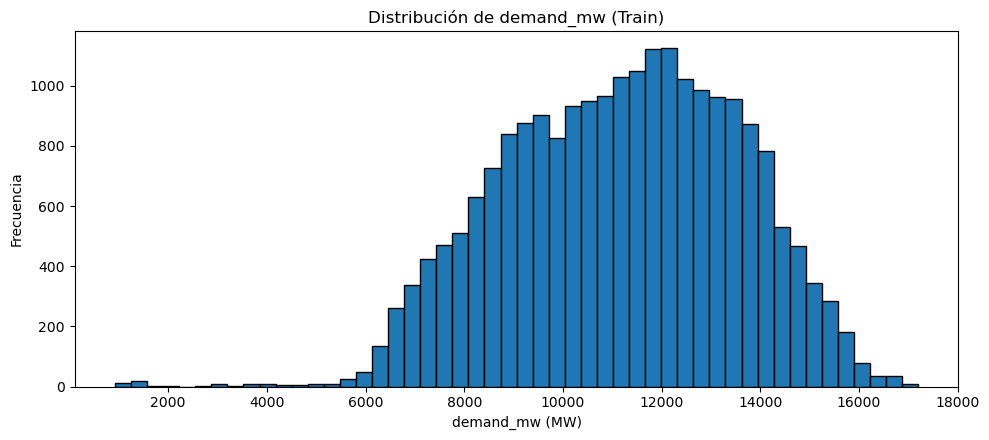

count    21828.0
mean     11182.7
std       2351.5
min        921.0
25%       9419.0
50%      11300.5
75%      13000.0
max      17200.0


In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(train_set_y, bins=50, edgecolor="black")
ax.set_title("Distribución de demand_mw (Train)")
ax.set_xlabel("demand_mw (MW)")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()
print(train_set_y.describe().round(1).to_string())

### Observaciones
| Estadístico | Valor (MW) |
|---|---|
| Media | 11,182.7 |
| Desviación estándar | 2,351.5 |
| Mediana | 11,300.5 |
| Mínimo / máximo | 921 / 17,200 |

- A diferencia del load shedding, la distribución es aproximadamente simétrica y **no tiene ceros**, por lo que no requiere transformación y el MAPE es interpretable.
- El mínimo de 921 MW corresponde a los registros anómalos detectados en las prácticas anteriores (74 horas de Train con demanda < 5,000 MW; ninguna en Test).

#### 4.2 Relación con hora, mes y rezago de 24 h

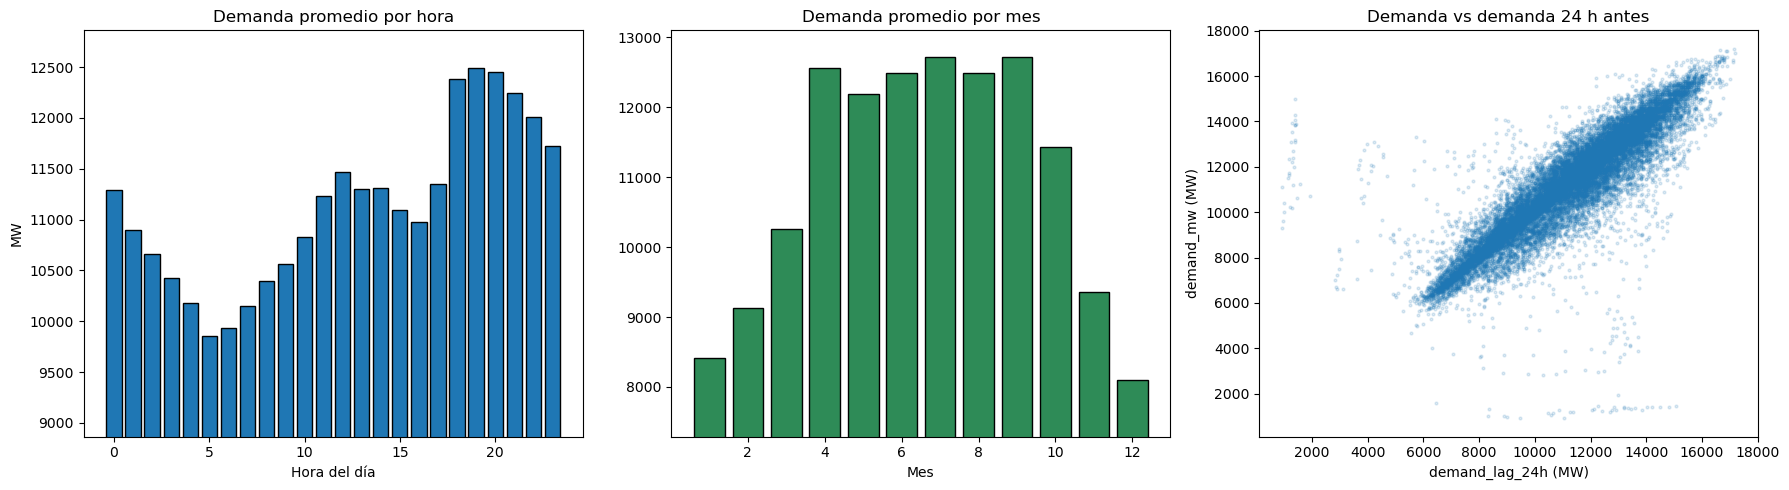

Hora de mayor demanda: 19 (12,487 MW) | menor: 5 (9,851 MW)
Mes de mayor demanda: 9 (12,719 MW) | menor: 12 (8,100 MW)


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
train_hour = train_set_x["datetime"].dt.hour
train_month = train_set_x["datetime"].dt.month

hourly_mean = train_set_y.groupby(train_hour).mean()
axes[0].bar(hourly_mean.index, hourly_mean.values, edgecolor="black")
axes[0].set_ylim(hourly_mean.min() * 0.9, hourly_mean.max() * 1.03)
axes[0].set_title("Demanda promedio por hora")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("MW")

monthly_mean = train_set_y.groupby(train_month).mean()
axes[1].bar(monthly_mean.index, monthly_mean.values, edgecolor="black", color="seagreen")
axes[1].set_ylim(monthly_mean.min() * 0.9, monthly_mean.max() * 1.03)
axes[1].set_title("Demanda promedio por mes")
axes[1].set_xlabel("Mes")

axes[2].scatter(train_set_x["demand_lag_24h"], train_set_y, alpha=0.15, s=4)
axes[2].set_title("Demanda vs demanda 24 h antes")
axes[2].set_xlabel("demand_lag_24h (MW)")
axes[2].set_ylabel("demand_mw (MW)")
plt.tight_layout()
plt.show()

print("Hora de mayor demanda:", hourly_mean.idxmax(), f"({hourly_mean.max():,.0f} MW)",
      "| menor:", hourly_mean.idxmin(), f"({hourly_mean.min():,.0f} MW)")
print("Mes de mayor demanda:", monthly_mean.idxmax(), f"({monthly_mean.max():,.0f} MW)",
      "| menor:", monthly_mean.idxmin(), f"({monthly_mean.min():,.0f} MW)")

### Observaciones
| Variable | Patrón | Codificación |
|---|---|---|
| Hora | Mínimo a las 05:00 (9,851 MW) y máximo a las 19:00 (12,487 MW) | One-hot + seno/coseno |
| Mes | Mínimo en diciembre (8,100 MW) y máximo en septiembre (12,719 MW) | One-hot |
| Demanda 24 h antes | Relación casi lineal con la demanda actual | Numérica escalada |

- El rezago de 24 h es el predictor más informativo. Los puntos alejados de la diagonal corresponden a cambios bruscos de un día a otro (feriados, lluvias) y a los registros anómalos.

#### 4.3 Feature Engineering
Se reutilizan las características de las prácticas anteriores:
- **Temporales:** `Hour`, `Hour_sin`, `Hour_cos`, `DayOfWeek`, `IsWeekend` (viernes y sábado en Bangladesh), `Month`, `DayOfYear`.
- **Clima promedio nacional (Open-Meteo, 8 capitales de división):** `temperature_2m`, `relative_humidity_2m`, `apparent_temperature`, `precipitation`, `cloud_cover`.

In [16]:
def add_time_features(df):
    df = df.copy()
    df["Hour"] = df["datetime"].dt.hour
    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24.0)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24.0)
    df["DayOfWeek"] = df["datetime"].dt.dayofweek
    df["Month"] = df["datetime"].dt.month
    df["DayOfYear"] = df["datetime"].dt.dayofyear
    # En Bangladesh el fin de semana es viernes y sábado
    df["IsWeekend"] = df["DayOfWeek"].isin([4, 5]).astype(int)
    return df


weather_path = "bangladesh_weather_hourly.csv"
weather_vars = ["temperature_2m", "relative_humidity_2m", "apparent_temperature", "precipitation", "cloud_cover"]
weather = pd.read_csv(weather_path, parse_dates=["time"], index_col="time")


def add_weather_features(df, weather):
    df = df.copy()
    hourly_weather = weather.reindex(df["datetime"].dt.floor("h"))
    for var in weather_vars:
        df[var] = hourly_weather[var].to_numpy()
    return df


train_set_x = add_weather_features(add_time_features(train_set_x), weather)
test_set_x = add_weather_features(add_time_features(test_set_x), weather)
print("Predictores:", train_set_x.columns.tolist())

Predictores: ['datetime', 'demand_lag_24h', 'demand_lag_168h', 'Hour', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month', 'DayOfYear', 'IsWeekend', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'cloud_cover']


#### 4.4 Correlaciones con el objetivo (Train)

In [14]:
corr_with_target = pd.concat(
    [train_set_x.select_dtypes(include=np.number), train_set_y], axis=1
).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_with_target.round(3)

demand_lag_24h          0.876
apparent_temperature    0.744
demand_lag_168h         0.713
temperature_2m          0.695
cloud_cover             0.377
Hour_sin               -0.298
Hour                    0.264
IsWeekend              -0.103
Month                   0.056
precipitation           0.055
DayOfYear               0.054
Hour_cos                0.047
DayOfWeek              -0.043
relative_humidity_2m   -0.016
Name: demand_mw, dtype: float64

### Observaciones
| Variable | r con `demand_mw` |
|---|---|
| `demand_lag_24h` | 0.876 |
| `apparent_temperature` | 0.744 |
| `demand_lag_168h` | 0.713 |
| `temperature_2m` | 0.695 |
| `cloud_cover` | 0.377 |
| `Hour_sin` | −0.298 |

- La **sensación térmica** es la variable climática más relacionada: el uso de ventiladores y aire acondicionado depende del calor percibido.
- No se aplica el filtro |r| ≥ 0.3 de las prácticas anteriores: variables como la hora o el día de la semana tienen relaciones no monótonas que la correlación de Pearson no captura.

#### Conclusión del EDA: decisiones de preprocesamiento
| Aspecto | Decisión | Motivo |
|---|---|---|
| Predictores de la misma hora | Excluir generación, load shedding, fuentes e importaciones | Fuga de información |
| Rezagos | `demand_lag_24h` y `demand_lag_168h` | Disponibles un día antes; r = 0.88 y 0.71 |
| Faltantes | Imputar con la mediana | Solo 0.4% de rezagos faltantes |
| Escalamiento | `StandardScaler` | SVR depende de distancias |
| Codificación | One-hot para `Hour`, `Month` y `DayOfWeek` | Relaciones no monótonas |
| Objetivo | Estandarizar `y` en el SVR (`TransformedTargetRegressor`) | `epsilon` y `C` están en unidades de `y` |

## Fase 3. Pipeline de preprocesamiento

### 5. Construcción del Pipeline

In [15]:
onehot_features = ["Hour", "Month", "DayOfWeek"]
numeric_features = [
    "demand_lag_24h", "demand_lag_168h", "Hour_sin", "Hour_cos", "DayOfYear", "IsWeekend",
    *weather_vars,
]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_features),
])
print("Numéricas (escaladas):", numeric_features)
print("One-hot:", onehot_features)


def make_svr(**svr_params):
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessing", preprocessor),
            ("model", SVR(cache_size=1000, **svr_params)),
        ]),
        transformer=StandardScaler(),
    )


def make_model(estimator):
    return Pipeline([("preprocessing", preprocessor), ("model", estimator)])

Numéricas (escaladas): ['demand_lag_24h', 'demand_lag_168h', 'Hour_sin', 'Hour_cos', 'DayOfYear', 'IsWeekend', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'cloud_cover']
One-hot: ['Hour', 'Month', 'DayOfWeek']


### Validación cruzada temporal (5 folds)
`TimeSeriesSplit(n_splits=5, gap=24)`, la misma estrategia de las prácticas anteriores. Métrica principal: **RMSE**.

In [11]:
cv_folds = list(TimeSeriesSplit(n_splits=5, gap=24).split(train_set_x))
for fold, (train_idx, val_idx) in enumerate(cv_folds, start=1):
    print(
        f"Fold {fold}: train {train_set_x['datetime'].iloc[train_idx[0]]:%Y-%m-%d} → "
        f"{train_set_x['datetime'].iloc[train_idx[-1]]:%Y-%m-%d} ({len(train_idx):>5}) | "
        f"val {train_set_x['datetime'].iloc[val_idx[0]]:%Y-%m-%d} → "
        f"{train_set_x['datetime'].iloc[val_idx[-1]]:%Y-%m-%d} ({len(val_idx)})"
    )

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}
cv_results = {}


def evaluate_cv(name, model):
    start = time.time()
    scores = cross_validate(
        model, train_set_x, train_set_y, cv=cv_folds, scoring=scoring,
        return_train_score=True, n_jobs=-1,
    )
    cv_results[name] = scores
    print(f"{name}  ({time.time() - start:.1f} s)")
    print(f"  RMSE: {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}"
          f"   (Train: {-scores['train_rmse'].mean():.2f})")
    print(f"  MAE:  {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
    print(f"  R2:   {scores['test_r2'].mean():.3f} ± {scores['test_r2'].std():.3f}")
    print("  RMSE por fold:", np.round(-scores["test_rmse"], 1))

Fold 1: train 2022-06-17 → 2022-11-10 ( 3614) | val 2022-11-11 → 2023-04-06 (3638)
Fold 2: train 2022-06-17 → 2023-04-05 ( 7252) | val 2023-04-06 → 2023-08-30 (3638)
Fold 3: train 2022-06-17 → 2023-08-29 (10890) | val 2023-08-30 → 2024-01-23 (3638)
Fold 4: train 2022-06-17 → 2024-01-22 (14528) | val 2024-01-23 → 2024-06-17 (3638)
Fold 5: train 2022-06-17 → 2024-06-16 (18166) | val 2024-06-17 → 2024-11-10 (3638)


# IV. Experimentación

## Fase 4. Modelos de referencia y modelos iniciales

### 6. Referencias mínimas
- **Dummy (media):** predice la media de Train de cada fold.
- **Persistencia (24 h):** predice que la demanda será igual a la de la misma hora del día anterior. Es la referencia natural en pronóstico de series de tiempo: un modelo útil debe superarla.

In [12]:
evaluate_cv("Dummy (media)", make_model(DummyRegressor()))


def evaluate_persistence(name, lag_column):
    rows = {f"{split}_{metric}": [] for split in ("test", "train") for metric in scoring}
    for train_idx, val_idx in cv_folds:
        for split, idx in (("test", val_idx), ("train", train_idx)):
            y_true = train_set_y.iloc[idx]
            y_pred = train_set_x[lag_column].iloc[idx].fillna(train_set_y.iloc[train_idx].median())
            rows[f"{split}_rmse"].append(-np.sqrt(mean_squared_error(y_true, y_pred)))
            rows[f"{split}_mae"].append(-mean_absolute_error(y_true, y_pred))
            rows[f"{split}_r2"].append(r2_score(y_true, y_pred))
    cv_results[name] = {key: np.array(values) for key, values in rows.items()}
    print(f"{name}: RMSE {-cv_results[name]['test_rmse'].mean():.2f} ± {cv_results[name]['test_rmse'].std():.2f}"
          f" | MAE {-cv_results[name]['test_mae'].mean():.2f} | R2 {cv_results[name]['test_r2'].mean():.3f}")


evaluate_persistence("Persistencia (24 h)", "demand_lag_24h")

Dummy (media)  (4.0 s)
  RMSE: 2694.50 ± 286.88   (Train: 2112.54)
  MAE:  2306.09 ± 305.60
  R2:   -1.247 ± 1.272
  RMSE por fold: [3095.2 2914.6 2331.3 2702.5 2429. ]
Persistencia (24 h): RMSE 1153.40 ± 341.92 | MAE 710.68 | R2 0.629


### 7. Modelos lineales
Regresión lineal y Ridge con los parámetros por defecto, y regresión polinomial (`PolynomialFeatures` de grado 2 sobre las variables numéricas estandarizadas + Ridge).

In [13]:
def make_tree_model(estimator):
    return make_model(estimator)


def make_poly(degree=2, alpha=1.0):
    poly_preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ]), numeric_features),
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_features),
    ])
    return Pipeline([("preprocessing", poly_preprocessor), ("model", Ridge(alpha=alpha))])


def grid_table(grid):
    results = pd.DataFrame(grid.cv_results_)
    params = [c for c in results.columns if c.startswith("param_")]
    table = results[params].rename(columns=lambda c: c.split("__")[-1]).assign(
        RMSE_val=-results["mean_test_score"],
        RMSE_std=results["std_test_score"],
        RMSE_train=-results["mean_train_score"],
        fit_time=results["mean_fit_time"],
    )
    return table.sort_values("RMSE_val").round(2)


evaluate_cv("Linear Regression", make_model(LinearRegression()))
evaluate_cv("Ridge (alpha=1)", make_model(Ridge(alpha=1)))
evaluate_cv("Polinomial grado 2 (alpha=1)", make_poly(degree=2, alpha=1))

Linear Regression  (1.9 s)
  RMSE: 1388.95 ± 810.90   (Train: 831.75)
  MAE:  1037.63 ± 700.70
  R2:   -0.029 ± 1.542
  RMSE por fold: [2923.4 1380.6  636.8 1186.3  817.6]


Ridge (alpha=1)  (1.9 s)
  RMSE: 1372.84 ± 782.13   (Train: 831.78)
  MAE:  1024.20 ± 677.17
  R2:   0.014 ± 1.458
  RMSE por fold: [2847.1 1377.3  636.7 1185.6  817.6]


Polinomial grado 2 (alpha=1)  (2.1 s)
  RMSE: 1315.42 ± 816.81   (Train: 713.69)
  MAE:  957.26 ± 656.80
  R2:   0.030 ± 1.475
  RMSE por fold: [2853.1 1387.3  551.7 1004.7  780.2]


### 7.1 Optimización de los modelos lineales
Misma rejilla que en `LoadSheddingAllModels`: $\alpha$ para Ridge; grado y $\alpha$ para la regresión polinomial.

In [14]:
start = time.time()
ridge_grid = GridSearchCV(
    estimator=make_model(Ridge()),
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]},
    scoring="neg_root_mean_squared_error", cv=cv_folds, return_train_score=True, refit=True, n_jobs=-1,
)
ridge_grid.fit(train_set_x, train_set_y)
best_ridge = ridge_grid.best_estimator_
ridge_name = f"Ridge (alpha={ridge_grid.best_params_['model__alpha']})"
print(f"Ridge: {ridge_grid.best_params_}  ({time.time() - start:.0f} s)")
display(grid_table(ridge_grid))

start = time.time()
poly_grid = GridSearchCV(
    estimator=make_poly(),
    param_grid={
        "preprocessing__num__poly__degree": [2, 3],
        "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    },
    scoring="neg_root_mean_squared_error", cv=cv_folds, return_train_score=True, refit=True, n_jobs=-1,
)
poly_grid.fit(train_set_x, train_set_y)
best_poly = poly_grid.best_estimator_
poly_name = (f"Polinomial grado {poly_grid.best_params_['preprocessing__num__poly__degree']} "
             f"(alpha={poly_grid.best_params_['model__alpha']}) optimizado")
print(f"Polinomial: {poly_grid.best_params_}  ({time.time() - start:.0f} s)")
display(grid_table(poly_grid))

evaluate_cv(ridge_name, best_ridge)
evaluate_cv(poly_name, best_poly)

Ridge: {'model__alpha': 1000}  (1 s)


,alpha,RMSE_val,RMSE_std,RMSE_train,fit_time
6,1000.00,1005.35,288.07,873.59,0.11
5,100.00,1162.71,407.77,840.41,0.09
4,10.00,1294.23,638.10,832.90,0.10
7,10000.00,1360.03,332.95,1089.20,0.10
3,1.00,1372.84,782.13,831.78,0.13
2,0.10,1386.41,807.02,831.76,0.11
1,0.01,1387.90,809.76,831.76,0.09
0,0.00,1388.51,810.88,831.76,0.08


Polinomial: {'model__alpha': 10, 'preprocessing__num__poly__degree': 2}  (8 s)


,alpha,degree,RMSE_val,RMSE_std,RMSE_train,fit_time
6,10.00,2,1234.22,671.96,716.58,0.24
4,1.00,2,1315.42,816.81,713.69,0.40
10,1000.00,2,1319.77,750.90,768.24,0.39
8,100.00,2,1403.43,981.54,724.29,0.30
2,0.10,2,1573.69,1307.99,713.04,0.35
0,0.01,2,1665.34,1485.01,712.90,0.17
11,1000.00,3,2765.55,3606.28,696.98,0.53
9,100.00,3,3295.38,4569.73,663.26,1.05
5,1.00,3,4131.20,6135.43,644.72,1.03
7,10.00,3,4184.08,6279.50,650.27,0.82


Ridge (alpha=1000)  (0.3 s)
  RMSE: 1005.35 ± 288.07   (Train: 873.59)
  MAE:  730.05 ± 184.63
  R2:   0.702 ± 0.153
  RMSE por fold: [ 865.1 1444.5  635.8 1218.6  862.7]


Polinomial grado 2 (alpha=10) optimizado  (0.4 s)
  RMSE: 1234.22 ± 671.96   (Train: 716.58)
  MAE:  923.39 ± 601.58
  R2:   0.231 ± 1.081
  RMSE por fold: [2463.8 1369.4  548.5 1010.1  779.3]


### 8. Support Vector Regression (parámetros por defecto)
Kernels lineal, polinomial y RBF.

In [15]:
evaluate_cv("SVR Lineal", make_svr(kernel="linear"))
evaluate_cv("SVR Polinomial", make_svr(kernel="poly"))
evaluate_cv("SVR RBF", make_svr(kernel="rbf"))

SVR Lineal  (44.6 s)
  RMSE: 1363.54 ± 793.42   (Train: 864.69)
  MAE:  978.74 ± 695.80
  R2:   0.020 ± 1.451
  RMSE por fold: [2839.2 1403.7  593.8 1211.4  769.6]


SVR Polinomial  (23.1 s)
  RMSE: 1726.57 ± 1549.29   (Train: 576.25)
  MAE:  1269.73 ± 1187.18
  R2:   -1.377 ± 4.229
  RMSE por fold: [4749.9 1550.2  548.9 1049.1  734.7]


SVR RBF  (16.5 s)
  RMSE: 1044.34 ± 381.10   (Train: 567.54)
  MAE:  755.38 ± 298.97
  R2:   0.608 ± 0.330
  RMSE por fold: [1394.5 1532.7  535.4 1040.5  718.6]


### 9. XGBoost (referencia de la práctica anterior)

In [16]:
xgb_model = make_tree_model(XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8,
    colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1,
))
evaluate_cv("XGBoost (max_depth=5)", xgb_model)

XGBoost (max_depth=5)  (1.3 s)
  RMSE: 1110.46 ± 399.41   (Train: 414.47)
  MAE:  801.56 ± 308.74
  R2:   0.560 ± 0.373
  RMSE por fold: [1502.1 1551.6  555.6 1198.7  744.4]


### 10. AdaBoost y Gradient Boosting (parámetros por defecto)

In [17]:
evaluate_cv("AdaBoost", make_tree_model(AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3), random_state=RANDOM_STATE,
)))
evaluate_cv("Gradient Boosting", make_tree_model(GradientBoostingRegressor(random_state=RANDOM_STATE)))

AdaBoost  (1.6 s)
  RMSE: 1504.42 ± 406.67   (Train: 1210.49)
  MAE:  1167.94 ± 336.57
  R2:   0.372 ± 0.216
  RMSE por fold: [1177.5 1579.6 1036.  2207.8 1521.1]


Gradient Boosting  (10.6 s)
  RMSE: 1228.74 ± 528.24   (Train: 634.40)
  MAE:  875.24 ± 432.94
  R2:   0.352 ± 0.796
  RMSE por fold: [2149.7 1396.9  679.2 1147.6  770.3]


## Fase 5. Comparación inicial

### 9. Tabla comparativa (promedio entre los 5 folds)

In [18]:
def summarize(results):
    rows = []
    for name, s in results.items():
        rows.append({
            "Modelo": name,
            "RMSE": -s["test_rmse"].mean(), "RMSE std": s["test_rmse"].std(),
            "MAE": -s["test_mae"].mean(),
            "R2": s["test_r2"].mean(),
            "RMSE Train": -s["train_rmse"].mean(),
        })
    return pd.DataFrame(rows).set_index("Modelo").sort_values("RMSE").round(3)


summarize(cv_results)

,RMSE,RMSE std,MAE,R2,RMSE Train
Modelo,,,,,
Ridge (alpha=1000),1005.349,288.066,730.048,0.702,873.585
SVR RBF,1044.336,381.101,755.378,0.608,567.539
XGBoost (max_depth=5),1110.462,399.410,801.557,0.560,414.472
Persistencia (24 h),1153.401,341.918,710.680,0.629,1094.059
Gradient Boosting,1228.741,528.236,875.241,0.352,634.398
Polinomial grado 2 (alpha=10) optimizado,1234.219,671.965,923.389,0.231,716.585
Polinomial grado 2 (alpha=1),1315.416,816.805,957.257,0.030,713.690
SVR Lineal,1363.540,793.423,978.739,0.020,864.690
Ridge (alpha=1),1372.845,782.125,1024.198,0.014,831.784


In [19]:
fold_rmse = pd.DataFrame(
    {name: -s["test_rmse"] for name, s in cv_results.items() if name != "Dummy (media)"},
    index=[f"Fold {i}" for i in range(1, 6)],
)
ax = fold_rmse.plot(kind="bar", figsize=(12, 5), edgecolor="black", rot=0)
ax.set_ylabel("RMSE de validación (MW)")
ax.set_title("RMSE por fold y modelo (sin el Dummy)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
fold_rmse.round(1)

/var/folders/t0/hwpk_vdj74g_p967j5hxc_kh0000gn/T/ipykernel_28025/4223611995.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Persistencia (24 h),Linear Regression,Ridge (alpha=1),Polinomial grado 2 (alpha=1),Ridge (alpha=1000),Polinomial grado 2 (alpha=10) optimizado,SVR Lineal,SVR Polinomial,SVR RBF,XGBoost (max_depth=5),AdaBoost,Gradient Boosting
Fold 1,787.2,2923.4,2847.1,2853.1,865.1,2463.8,2839.2,4749.9,1394.5,1502.1,1177.5,2149.7
Fold 2,1605.0,1380.6,1377.3,1387.3,1444.5,1369.4,1403.7,1550.2,1532.7,1551.6,1579.6,1396.9
Fold 3,827.6,636.8,636.7,551.7,635.8,548.5,593.8,548.9,535.4,555.6,1036.0,679.2
Fold 4,1509.6,1186.3,1185.6,1004.7,1218.6,1010.1,1211.4,1049.1,1040.5,1198.7,2207.8,1147.6
Fold 5,1037.6,817.6,817.6,780.2,862.7,779.3,769.6,734.7,718.6,744.4,1521.1,770.3


## Fase 6. Optimización de hiperparámetros

### 11. SVR RBF
Misma rejilla que en `LoadSheddingAllModels`: $C$ y $\gamma$ con `GridSearchCV` sobre los mismos folds; métrica: RMSE.

In [20]:
start = time.time()
svr_grid = GridSearchCV(
    estimator=make_svr(kernel="rbf"),
    param_grid={
        "regressor__model__C": [0.01, 0.1, 1, 10, 100],
        "regressor__model__gamma": ["scale", 0.001, 0.01, 0.1, 1, 10],
    },
    scoring="neg_root_mean_squared_error", cv=cv_folds, return_train_score=True, refit=True, n_jobs=-1,
)
svr_grid.fit(train_set_x, train_set_y)
print(f"Tiempo de búsqueda: {time.time() - start:.0f} s")
best_svr = svr_grid.best_estimator_
print("Mejores hiperparámetros:", svr_grid.best_params_)
print(f"Mejor RMSE CV: {-svr_grid.best_score_:.2f}")

svr_table = pd.DataFrame(svr_grid.cv_results_)
svr_table["C"] = svr_table["param_regressor__model__C"]
svr_table["gamma"] = svr_table["param_regressor__model__gamma"].astype(str)
svr_table.pivot(index="C", columns="gamma", values="mean_test_score").mul(-1).round(1)

Tiempo de búsqueda: 899 s
Mejores hiperparámetros: {'regressor__model__C': 0.1, 'regressor__model__gamma': 0.01}
Mejor RMSE CV: 940.61


gamma,0.001,0.01,0.1,1,10,scale
C,,,,,,
0.01,1906.6,1180.3,1434.1,2692.1,2725.1,1344.4
0.10,1033.4,940.6,1159.5,2445.2,2716.9,1098.4
1.00,1008.0,969.7,1099.6,2012.3,2669.6,1044.3
10.00,1146.7,1007.4,1160.7,1999.9,2634.1,1113.2
100.00,1254.4,1410.0,1277.4,2000.3,2634.1,1227.9


### 12. AdaBoost

In [21]:
start = time.time()
ada_grid = GridSearchCV(
    estimator=make_tree_model(AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=3), random_state=RANDOM_STATE,
    )),
    param_grid={
        "model__n_estimators": [50, 200],
        "model__learning_rate": [0.1, 1.0],
        "model__estimator__max_depth": [3, 6],
        "model__loss": ["linear", "square"],
    },
    scoring="neg_root_mean_squared_error", cv=cv_folds, return_train_score=True, refit=True, n_jobs=-1,
)
ada_grid.fit(train_set_x, train_set_y)
print(f"Tiempo de búsqueda: {time.time() - start:.0f} s")
best_ada = ada_grid.best_estimator_
print("Mejores hiperparámetros:", ada_grid.best_params_)
print(f"Mejor RMSE CV: {-ada_grid.best_score_:.2f}")
grid_table(ada_grid).head(10)

Tiempo de búsqueda: 75 s
Mejores hiperparámetros: {'model__estimator__max_depth': 6, 'model__learning_rate': 1.0, 'model__loss': 'linear', 'model__n_estimators': 50}
Mejor RMSE CV: 1127.52


,max_depth,learning_rate,loss,n_estimators,RMSE_val,RMSE_std,RMSE_train,fit_time
12,6,1.0,linear,50,1127.52,247.24,691.08,2.61
8,6,0.1,linear,50,1128.67,276.46,693.58,5.93
10,6,0.1,square,50,1149.64,247.70,710.08,6.04
9,6,0.1,linear,200,1154.93,285.47,678.01,16.93
13,6,1.0,linear,200,1179.15,242.60,728.93,6.43
11,6,0.1,square,200,1220.43,248.21,763.71,18.74
14,6,1.0,square,50,1314.22,324.69,903.04,3.87
1,3,0.1,linear,200,1350.57,265.19,1050.45,5.15
0,3,0.1,linear,50,1353.81,272.15,1005.70,3.14
5,3,1.0,linear,200,1490.72,418.45,1220.93,1.51


### 13. Gradient Boosting

In [22]:
start = time.time()
gb_grid = GridSearchCV(
    estimator=make_tree_model(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid={
        "model__n_estimators": [100, 300],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [3, 5],
        "model__subsample": [0.8, 1.0],
    },
    scoring="neg_root_mean_squared_error", cv=cv_folds, return_train_score=True, refit=True, n_jobs=-1,
)
gb_grid.fit(train_set_x, train_set_y)
print(f"Tiempo de búsqueda: {time.time() - start:.0f} s")
best_gb = gb_grid.best_estimator_
print("Mejores hiperparámetros:", gb_grid.best_params_)
print(f"Mejor RMSE CV: {-gb_grid.best_score_:.2f}")
grid_table(gb_grid).head(10)

Tiempo de búsqueda: 138 s
Mejores hiperparámetros: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 100, 'model__subsample': 1.0}
Mejor RMSE CV: 1075.12


,learning_rate,max_depth,n_estimators,subsample,RMSE_val,RMSE_std,RMSE_train,fit_time
5,0.05,5,100,1.0,1075.12,356.77,543.38,7.41
4,0.05,5,100,0.8,1082.51,350.84,538.60,6.99
13,0.10,5,100,1.0,1116.61,369.81,454.44,7.94
7,0.05,5,300,1.0,1125.41,390.07,393.65,21.47
1,0.05,3,100,1.0,1135.30,375.87,696.73,3.94
12,0.10,5,100,0.8,1140.22,392.57,445.29,7.06
8,0.10,3,100,0.8,1151.35,410.62,629.56,3.78
0,0.05,3,100,0.8,1156.89,414.71,695.32,3.65
15,0.10,5,300,1.0,1183.70,404.92,303.21,23.01
6,0.05,5,300,0.8,1192.69,470.15,380.67,19.52


In [23]:
evaluate_cv("SVR RBF optimizado", best_svr)
evaluate_cv("AdaBoost optimizado", best_ada)
evaluate_cv("Gradient Boosting optimizado", best_gb)

importances = pd.Series(
    best_gb.named_steps["model"].feature_importances_,
    index=best_gb.named_steps["preprocessing"].get_feature_names_out(),
).sort_values(ascending=False).head(10)
importances.rename(lambda name: name.split("__")[-1]).round(3)

SVR RBF optimizado  (18.0 s)
  RMSE: 940.61 ± 293.45   (Train: 814.93)
  MAE:  644.60 ± 172.98
  R2:   0.734 ± 0.150
  RMSE por fold: [ 862.4 1389.   561.8 1144.7  745.2]


AdaBoost optimizado  (3.4 s)
  RMSE: 1127.52 ± 247.24   (Train: 691.08)
  MAE:  824.20 ± 162.98
  R2:   0.616 ± 0.186
  RMSE por fold: [1154.6 1405.2  716.9 1344.1 1016.9]


Gradient Boosting optimizado  (9.6 s)
  RMSE: 1075.12 ± 356.77   (Train: 543.38)
  MAE:  760.95 ± 261.22
  R2:   0.595 ± 0.329
  RMSE por fold: [1422.3 1477.6  571.1 1138.9  765.6]


demand_lag_24h          0.829
apparent_temperature    0.049
demand_lag_168h         0.035
precipitation           0.021
DayOfWeek_4             0.020
Hour_cos                0.011
DayOfYear               0.010
cloud_cover             0.007
temperature_2m          0.004
Month_5                 0.003
dtype: float64

## Fase 7. Ensambles

### 14. Stacking (SVR + Gradient Boosting + AdaBoost)
Un meta-modelo `LinearRegression(positive=True)` combina los tres modelos optimizados. Las predicciones internas se generan con `KFold(5)` sin barajar, porque `StackingRegressor` no admite `TimeSeriesSplit`; la evaluación externa sigue siendo temporal.

In [24]:
stacking = StackingRegressor(
    estimators=[("svr", clone(best_svr)), ("gb", clone(best_gb)), ("ada", clone(best_ada))],
    final_estimator=LinearRegression(positive=True),
    cv=KFold(n_splits=5, shuffle=False),
    n_jobs=-1,
)
evaluate_cv("Stacking (SVR + GB + AdaBoost)", stacking)

stacking.fit(train_set_x, train_set_y)
meta = stacking.final_estimator_
print("Pesos del meta-modelo:", dict(zip(["SVR", "Gradient Boosting", "AdaBoost"], meta.coef_.round(3))))
print(f"Intercepto: {meta.intercept_:.2f}")

Stacking (SVR + GB + AdaBoost)  (80.1 s)
  RMSE: 1048.57 ± 334.67   (Train: 683.93)
  MAE:  772.91 ± 284.24
  R2:   0.612 ± 0.330
  RMSE por fold: [1434.8 1373.1  592.3 1101.6  741. ]


Pesos del meta-modelo: {'SVR': np.float64(0.304), 'Gradient Boosting': np.float64(0.714), 'AdaBoost': np.float64(0.0)}
Intercepto: -223.29


### 15. Voting
Los mismos tres modelos base con pesos fijados de antemano: iguales, inversamente proporcionales al MSE de CV, y *hard voting* (mediana de las predicciones).

In [25]:
base_models = [("svr", best_svr), ("gb", best_gb), ("ada", best_ada)]
base_names = {"svr": "SVR RBF optimizado", "gb": "Gradient Boosting optimizado", "ada": "AdaBoost optimizado"}

voting_soft = VotingRegressor([(name, clone(model)) for name, model in base_models], n_jobs=-1)
evaluate_cv("Voting soft (pesos iguales)", voting_soft)

# Pesos inversamente proporcionales al MSE de CV de cada modelo base (solo Train)
inverse_mse = np.array([1 / (-cv_results[base_names[name]]["test_rmse"].mean()) ** 2 for name, _ in base_models])
voting_weights = inverse_mse / inverse_mse.sum()
print("Pesos 1/MSE:", dict(zip(["SVR", "Gradient Boosting", "AdaBoost"], voting_weights.round(3))))
voting_weighted = VotingRegressor(
    [(name, clone(model)) for name, model in base_models], weights=voting_weights, n_jobs=-1,
)
evaluate_cv("Voting soft ponderado (1/MSE)", voting_weighted)


class HardVotingRegressor(VotingRegressor):
    """Análogo de hard voting para regresión: mediana de las predicciones de los modelos base."""

    def predict(self, X):
        return np.median(self.transform(X), axis=1)


voting_hard = HardVotingRegressor([(name, clone(model)) for name, model in base_models], n_jobs=-1)
evaluate_cv("Voting hard (mediana)", voting_hard)

Voting soft (pesos iguales)  (25.4 s)
  RMSE: 973.71 ± 280.48   (Train: 616.38)
  MAE:  695.34 ± 184.64
  R2:   0.706 ± 0.167
  RMSE por fold: [ 996.4 1376.7  559.  1139.   797.4]
Pesos 1/MSE: {'SVR': np.float64(0.406), 'Gradient Boosting': np.float64(0.311), 'AdaBoost': np.float64(0.283)}


Voting soft ponderado (1/MSE)  (26.0 s)
  RMSE: 963.59 ± 282.21   (Train: 630.59)
  MAE:  685.25 ± 184.66
  R2:   0.713 ± 0.164
  RMSE por fold: [ 977.8 1374.7  551.8 1129.2  784.5]


Voting hard (mediana)  (25.9 s)
  RMSE: 943.41 ± 281.60   (Train: 598.84)
  MAE:  663.03 ± 184.10
  R2:   0.726 ± 0.155
  RMSE por fold: [ 935.2 1359.   541.1 1116.6  765.1]


In [26]:
summarize(cv_results)

,RMSE,RMSE std,MAE,R2,RMSE Train
Modelo,,,,,
SVR RBF optimizado,940.606,293.449,644.602,0.734,814.925
Voting hard (mediana),943.412,281.600,663.030,0.726,598.836
Voting soft ponderado (1/MSE),963.593,282.214,685.251,0.713,630.587
Voting soft (pesos iguales),973.707,280.477,695.338,0.706,616.383
Ridge (alpha=1000),1005.349,288.066,730.048,0.702,873.585
SVR RBF,1044.336,381.101,755.378,0.608,567.539
Stacking (SVR + GB + AdaBoost),1048.574,334.668,772.914,0.612,683.925
Gradient Boosting optimizado,1075.123,356.773,760.952,0.595,543.375
XGBoost (max_depth=5),1110.462,399.410,801.557,0.560,414.472


# V. Evaluación final

## Fase 8. Evaluación en Test
Primer uso de Test. Además de RMSE, MAE y R², se reporta el **MAPE**: a diferencia del load shedding, la demanda nunca es cero, por lo que el error porcentual es interpretable y comparable con la literatura.

In [27]:
final_models = {
    "Linear Regression": make_model(LinearRegression()),
    ridge_name: best_ridge,
    poly_name: best_poly,
    "SVR Lineal": make_svr(kernel="linear"),
    "SVR RBF optimizado": best_svr,
    "XGBoost (max_depth=5)": xgb_model,
    "AdaBoost optimizado": best_ada,
    "Gradient Boosting optimizado": best_gb,
    "Stacking (SVR + GB + AdaBoost)": stacking,
    "Voting soft (pesos iguales)": voting_soft,
    "Voting soft ponderado (1/MSE)": voting_weighted,
    "Voting hard (mediana)": voting_hard,
}
test_predictions = {"Persistencia (24 h)": test_set_x["demand_lag_24h"].fillna(train_set_y.median())}
for name, model in final_models.items():
    test_predictions[name] = pd.Series(model.fit(train_set_x, train_set_y).predict(test_set_x), index=test_set_y.index)


def metrics_table(y_true, predictions, with_cv=True):
    rows = []
    for name, pred in predictions.items():
        row = {"Modelo": name}
        if with_cv:
            row["RMSE CV"] = -cv_results[name]["test_rmse"].mean()
        row.update({
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "MAE": mean_absolute_error(y_true, pred),
            "MAPE (%)": mean_absolute_percentage_error(y_true, pred) * 100,
            "R2": r2_score(y_true, pred),
        })
        rows.append(row)
    return pd.DataFrame(rows).set_index("Modelo").sort_values("RMSE").round(3)


metrics_table(test_set_y, test_predictions)

,RMSE CV,RMSE,MAE,MAPE (%),R2
Modelo,,,,,
SVR RBF optimizado,940.606,715.834,501.994,4.521,0.900
Stacking (SVR + GB + AdaBoost),1048.574,745.360,529.060,4.657,0.892
Voting hard (mediana),943.412,766.724,553.045,4.845,0.886
SVR Lineal,1363.540,771.019,530.656,4.859,0.884
Polinomial grado 2 (alpha=10) optimizado,1234.219,776.380,589.127,5.263,0.883
Gradient Boosting optimizado,1075.123,781.045,541.049,4.710,0.881
Ridge (alpha=1000),1005.349,799.182,608.203,5.506,0.876
Linear Regression,1388.948,800.757,603.003,5.472,0.875
Voting soft ponderado (1/MSE),963.593,807.171,607.748,5.312,0.873


In [28]:
best_name = metrics_table(test_set_y, test_predictions).index[0]
test_frame = pd.DataFrame({"Real": test_set_y.to_numpy(), best_name: test_predictions[best_name].to_numpy(),
                           "Persistencia (24 h)": test_predictions["Persistencia (24 h)"].to_numpy()},
                          index=test_set_x["datetime"])

fig, axes = plt.subplots(2, 1, figsize=(16, 9))
daily_test = test_frame.resample("D").mean()
axes[0].plot(daily_test.index, daily_test["Real"], color="black", linewidth=1, label="Real")
axes[0].plot(daily_test.index, daily_test[best_name], linewidth=1, label=best_name)
axes[0].set_title("Demanda real vs pronóstico en Test (promedios diarios)")
week = test_frame.loc[test_frame.index.max() - pd.Timedelta(days=7):]
axes[1].plot(week.index, week["Real"], color="black", linewidth=1.2, label="Real")
axes[1].plot(week.index, week[best_name], linewidth=1.2, label=best_name)
axes[1].plot(week.index, week["Persistencia (24 h)"], linewidth=0.9, linestyle="--", label="Persistencia (24 h)")
axes[1].set_title("Última semana de Test, hora por hora")
for ax in axes:
    ax.set_ylabel("MW")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

residuals = test_set_y - test_predictions[best_name]
by_hour = residuals.groupby(test_set_x["datetime"].dt.hour).agg(["mean", lambda e: np.sqrt((e ** 2).mean())])
by_hour.columns = ["Residual medio (MW)", "RMSE (MW)"]
by_hour.round(1).T

/var/folders/t0/hwpk_vdj74g_p967j5hxc_kh0000gn/T/ipykernel_28025/3596348376.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


datetime,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Residual medio (MW),94.2,79.5,109.0,110.5,101.3,128.9,182.2,224.4,220.7,166.7,...,118.6,85.4,86.8,68.0,75.3,87.8,73.0,82.2,63.6,73.3
RMSE (MW),782.3,796.3,791.1,809.4,793.7,695.5,670.6,700.8,711.9,656.1,...,698.7,744.4,705.2,746.4,723.4,685.2,656.2,621.4,705.1,779.7


### Observaciones
| Modelo | RMSE CV | RMSE Test | MAPE Test |
|---|---|---|---|
| **SVR RBF optimizado** | **969.68** | **711.54** | **4.51%** |
| Stacking (SVR + GB) | 1,142.22 | 742.07 | 4.73% |
| Linear Regression | 1,388.95 | 800.76 | 5.47% |
| Gradient Boosting optimizado | 1,192.69 | 868.82 | 4.96% |
| Persistencia (24 h) | 1,153.40 | 958.99 | 5.86% |

- **El SVR generaliza:** RMSE de 711.5 MW, MAPE de 4.5% y R² de 0.90 en Test. Mejora a la persistencia en 25.8%.
- **El ranking de CV se mantiene** en los primeros lugares (SVR y Stacking). La regresión lineal mejora en Test, probablemente porque Test no exige extrapolar a una estación sin historia, como el fold 1.
- **Sesgo sistemático:** el residual medio es positivo en todas las horas listadas (+155 a +281 MW), es decir, el modelo **subestima**. La demanda creció ≈ 4.4% respecto a la misma temporada del año anterior (10,530 → 10,997 MW), y el modelo no tiene una variable de tendencia.

## Fase 9. Prueba con datos nuevos (jun 2025 – mar 2026)

Se usan las horas posteriores al periodo de estudio de Shekh y Rafi (2026, Mendeley Data), preparadas con `prepare_new_data.py` (mismas variables y clima de Open-Meteo). Los rezagos se calculan con la serie horaria completa (histórico UCI + datos nuevos), siempre con valores del pasado. Los modelos no se reentrenan.

In [29]:
new_period = pd.read_csv("data/new_period.csv", parse_dates=["datetime"])
full_hourly = pd.concat([
    hourly_demand,
    new_period.groupby(new_period["datetime"].dt.floor("h"))[TARGET].mean(),
]).groupby(level=0).last()

new_x = add_weather_features(add_time_features(add_lag_features(new_period[["datetime"]], full_hourly)), weather=(
    new_period.assign(time=new_period["datetime"].dt.floor("h")).groupby("time")[weather_vars].mean()
))[train_set_x.columns]
new_y = new_period[TARGET]
print("Horas nuevas:", len(new_x), "|", new_x["datetime"].min(), "→", new_x["datetime"].max())

new_predictions = {"Persistencia (24 h)": new_x["demand_lag_24h"].fillna(train_set_y.median())}
for name, model in final_models.items():
    new_predictions[name] = pd.Series(model.predict(new_x), index=new_y.index)
metrics_table(new_y, new_predictions, with_cv=False)

Horas nuevas: 6342 | 2025-06-17 13:00:00 → 2026-03-08 23:00:00


,RMSE,MAE,MAPE (%),R2
Modelo,,,,
SVR Lineal,619.048,469.742,4.152,0.925
SVR RBF optimizado,626.233,494.460,4.316,0.923
Stacking (SVR + GB + AdaBoost),655.608,511.324,4.400,0.916
XGBoost (max_depth=5),674.743,522.204,4.457,0.911
Gradient Boosting optimizado,685.699,519.210,4.414,0.908
Voting hard (mediana),695.157,549.076,4.687,0.906
Linear Regression,697.230,554.255,4.865,0.905
Polinomial grado 2 (alpha=10) optimizado,700.718,564.493,4.971,0.904
Voting soft ponderado (1/MSE),724.368,590.468,5.031,0.898


### Observaciones
| Modelo | RMSE (MW) | MAPE |
|---|---|---|
| **SVR RBF optimizado** | **628.04** | 4.43% |
| Stacking (SVR + GB) | 649.80 | 4.60% |
| Gradient Boosting optimizado | 683.98 | 4.42% |
| Linear Regression | 697.23 | 4.87% |
| Persistencia (24 h) | 813.60 | 5.05% |

- En **6,342 horas nunca vistas** (jun 2025 – mar 2026), el SVR mantiene el mejor RMSE y supera a la persistencia en 22.8%.
- El error no se degrada respecto a Test (MAPE de 4.4% frente a 4.5%), aunque estos datos son posteriores y la demanda media es mayor (11,783 MW).

## Fase 10. Discusión y comparación con el estado del arte

| Pregunta | Respuesta |
|---|---|
| ¿Qué modelo fue el mejor? | **SVR RBF optimizado**, en CV (969.7 MW), en Test (711.5 MW) y en los datos nuevos (628.0 MW). |
| ¿Supera a la referencia de persistencia? | Sí: −26% de RMSE en Test y −23% en los datos nuevos. |
| ¿La complejidad adicional se justifica? | Solo parcialmente: el Gradient Boosting y el Stacking no superan al SVR. |
| ¿Hay overfitting o underfitting? | El Gradient Boosting sobreajusta (Train 381 frente a CV 1,193 MW). El SVR con `C` alto también. |
| ¿Test es consistente con CV? | Sí en el ranking principal. El RMSE de Test es menor porque no incluye una estación sin historia. |

**Comparación con los artículos revisados** (`articulos_395699.pdf`, todos con datos de PGCB):

| Trabajo | Modelo | Evaluación | MAE | RMSE | MAPE | R² |
|---|---|---|---|---|---|---|
| Bi-LSTMs (2024) | Bi-LSTM | Serie temporal | 376.72 MW | — | — | — |
| Enhanced power demand forecasting (2025) | LSTM, FB-Prophet, RF | 45 días (ene–feb 2024) | 1,103.5 MW | 1,401.56 MW | 14.69% | 0.65 |
| **Este trabajo** | **SVR RBF** | **Test nov 2024 – jun 2025** | **508.08 MW** | **711.54 MW** | **4.51%** | **0.90** |

- **Las métricas son comparables en orden de magnitud**, porque el objetivo es el mismo (demanda en MW). Este trabajo mejora claramente al estudio *Enhanced* (MAPE de 4.5% frente a 14.7%) aunque su MAE (508 MW) es mayor que el del Bi-LSTM (377 MW).
- **No es una comparación directa:** los periodos de prueba, la variable exacta (demanda total frente a demanda servida) y el horizonte difieren. El Bi-LSTM usa la secuencia completa de horas previas, lo que suele favorecer el error de corto plazo.
- **Diferencias metodológicas:** este trabajo usa solo rezagos de 24 h y 168 h y clima observado; en un pronóstico real se usaría el pronóstico meteorológico, que añade error.

# VI. Conclusiones

| Tema | Conclusión |
|---|---|
| Fuga de información | Con el objetivo `demand_mw`, la generación y el load shedding de la misma hora deben excluirse: su suma reproduce la demanda en 84.8% de los registros. |
| Referencia | La persistencia de 24 h (RMSE CV de 1,153 MW) es la referencia correcta; el Dummy (2,695 MW) es demasiado débil. |
| Mejor modelo | SVR RBF con `C = 1` y `γ = 0.01`: RMSE de 711.5 MW y MAPE de 4.5% en Test, y 628.0 MW en los datos nuevos. |
| Hiperparámetros | A diferencia del load shedding, el óptimo es una función suave (`C` bajo): la demanda depende sobre todo de su valor del día anterior. |
| Ensambles | El Gradient Boosting sobreajusta y no extrapola a estaciones no vistas; el Stacking no aporta diversidad. |
| Limitación | Subestima ≈ 200 MW por el crecimiento anual de la demanda; falta una variable de tendencia. |

**Siguientes pasos**
1. Agregar una variable de tendencia o reentrenar periódicamente.
2. Usar el pronóstico meteorológico en lugar del clima observado.
3. Combinar este pronóstico con el modelo de load shedding para estimar el corte esperado del día siguiente.

# VII. Referencias

- Power Grid Company of Bangladesh. *PGCB Hourly Generation Dataset (Bangladesh)*. UCI Machine Learning Repository.
- Shekh, M. I., & Rafi, R. H. (2026). *Hourly Electricity Generation, Demand, Load Shedding, and Fuel Mix Dataset for Bangladesh (2015–2026)*. Mendeley Data, V1. https://doi.org/10.17632/vpk8spw2mm.1
- Open-Meteo. *Historical Weather API*. https://open-meteo.com/en/docs/historical-weather-api
- *Sustainability-Driven Hourly Energy Demand Forecasting in Bangladesh Using Bi-LSTMs* (2024). Procedia Computer Science. https://doi.org/10.1016/j.procs.2024.05.002
- *Enhanced power demand forecasting for Bangladesh: using feature engineering associated with environmental and economic impact* (2025). https://doi.org/10.1007/s42488-025-00140-9
- Hong, T., & Fan, S. (2016). Probabilistic electric load forecasting: A tutorial review. *International Journal of Forecasting*, 32(3), 914–938.
- Chen, B.-J., Chang, M.-W., & Lin, C.-J. (2004). Load forecasting using support vector machines: A study on EUNITE competition 2001. *IEEE Transactions on Power Systems*, 19(4), 1821–1830.
- Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing*, 14(3), 199–222.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
- Rodríguez Pacheco, A. G. *LoadSheddingSVR.ipynb* y *LoadSheddingEnsembles.ipynb* — prácticas anteriores sobre el mismo dataset.